# Praktikum 1 - Klasifikasi Gambar Day vs Night dengan Neural Network (Membangun & Ekspor Model)

**Nama:** Agus
**NIM:** 244107020049

[Sumber modul](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js15-pipeline-machine-learning-and-deployment/praktikum-1)

Dataset adalah lampiran modul (`images.zip`, 240 citra training dan 160 citra test). File ini identik dengan lampiran JS11
(SHA-256 sama, lihat `data/provenance.json`). Kode mengikuti Langkah 1-12 modul. Penyesuaiannya:
* Notebook dijalankan di Jupyter lokal (`.venv`), bukan Google Colab, sehingga `drive.mount` diganti ekstraksi `data/images.zip`
  dan path `/content/drive/MyDrive/FolderAnda/images/...` diganti `data/images/...`.
* Artefak model dan scaler disimpan langsung ke folder `daynight-project/`, yang dipakai Praktikum 2.
* Seed ditetapkan agar hasilnya reprodusibel.

In [1]:
import sys
import numpy as np
import tensorflow as tf
tf.keras.utils.set_random_seed(42)
print("Kernel:", sys.executable)
print("TensorFlow:", tf.__version__)

Kernel: /Users/jergal/College/machine-learning-smt-5/.venv/bin/python
TensorFlow: 2.21.0


#### Langkah 1: Import Library (pengganti Mount Google Drive)

In [2]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import cv2

from skimage.feature import hog
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras import layers, models

# Pengganti: from google.colab import drive; drive.mount('/content/drive')
from zipfile import ZipFile
with ZipFile('data/images.zip') as archive:
    for name in archive.namelist():
        if name.startswith('images/') and name.lower().endswith('.jpg'):
            assert '..' not in Path(name).parts
            if not (Path('data') / name).exists():
                archive.extract(name, 'data')

#### Langkah 2: Load Dataset

In [3]:
# Load images and labels from a directory structure
def load_dataset(img_dir):
    p = Path(img_dir)
    img_list = []
    for folder in sorted(p.glob('*')):
        label = folder.name
        for file in sorted(folder.glob('*.jpg')):
            img = cv2.imread(str(file))
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img_list.append((img, label))
    return img_list

train_dir = "data/images/training/"
test_dir  = "data/images/test"

train_img = load_dataset(train_dir)
test_img  = load_dataset(test_dir)

print(f"Jumlah data training: {len(train_img)}")
print(f"Jumlah data testing: {len(test_img)}")

Jumlah data training: 240
Jumlah data testing: 160


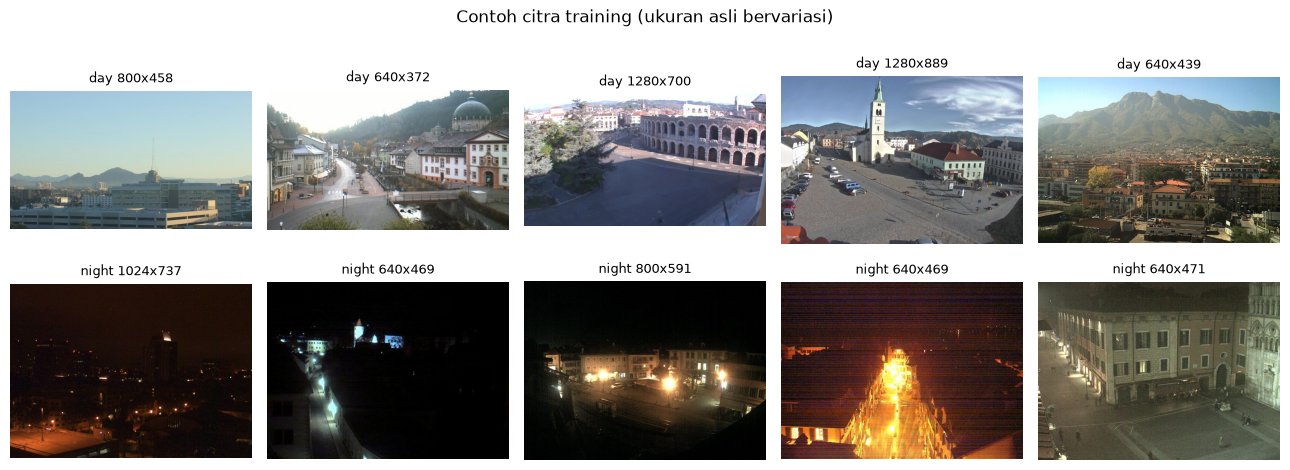

In [4]:
fig, ax = plt.subplots(2, 5, figsize=(13, 5))
for k, idx in enumerate([0, 30, 60, 90, 110, 120, 150, 180, 210, 239]):
    img, label = train_img[idx]
    ax.flat[k].imshow(img); ax.flat[k].set_title(f'{label} {img.shape[1]}x{img.shape[0]}', fontsize=9); ax.flat[k].axis('off')
plt.suptitle('Contoh citra training (ukuran asli bervariasi)'); plt.tight_layout(); plt.show()

#### Langkah 3: Preprocessing (Resize & Label Encoding)

In [5]:
# Preprocess images: resize and encode labels
def resize_image(img, size=(256,256)):
    return cv2.resize(img, size)

def label_encoder(label):
    return 1 if label == 'day' else 0

def preprocess(img_list):
    X = []
    y = []
    for img, label in img_list:
        img_std = resize_image(img)
        X.append(img_std)
        y.append(label_encoder(label))
    return X, y

X_train_img, y_train = preprocess(train_img)
X_test_img,  y_test  = preprocess(test_img)

#### Langkah 4: Ekstraksi Fitur HOG (Histogram of Oriented Gradients)

In [6]:
# Extract HOG features
def extract_hog(X_imgs):
    feats = []
    for img in X_imgs:
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        hog_feat = hog(gray,
                       orientations=9,
                       pixels_per_cell=(8,8),
                       cells_per_block=(2,2),
                       block_norm='L2-Hys',
                       visualize=False,
                       feature_vector=True)
        feats.append(hog_feat)
    return np.array(feats)

X_train_feat = extract_hog(X_train_img)
X_test_feat  = extract_hog(X_test_img)
print('Dimensi fitur HOG:', X_train_feat.shape)

Dimensi fitur HOG: (240, 34596)


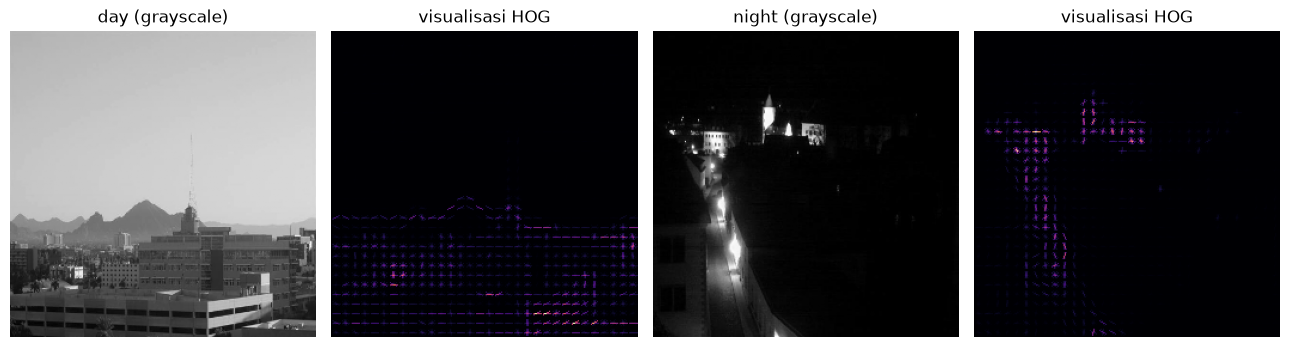

In [7]:
fig, ax = plt.subplots(1, 4, figsize=(13, 3.5))
for k, idx in enumerate([0, 150]):
    gray = cv2.cvtColor(X_train_img[idx], cv2.COLOR_RGB2GRAY)
    _, hog_img = hog(gray, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), block_norm='L2-Hys', visualize=True)
    ax[2 * k].imshow(gray, cmap='gray'); ax[2 * k].set_title(train_img[idx][1] + ' (grayscale)')
    ax[2 * k + 1].imshow(hog_img, cmap='magma'); ax[2 * k + 1].set_title('visualisasi HOG')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

#### Langkah 5: Normalisasi Fitur

In [8]:
# Normalize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_feat)
X_test_scaled  = scaler.transform(X_test_feat)

#### Langkah 6: Split Data Training & Validation

In [9]:
# Split training data for validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_scaled, y_train,
    test_size=0.2,
    random_state=42
)

#### Langkah 7: Konversi Label ke Numpy Array

In [10]:
# Convert labels to numpy arrays (required for Keras)
y_train = np.array(y_train)
y_val = np.array(y_val)
y_test = np.array(y_test)

#### Langkah 8: Membangun Arsitektur Model Neural Network

In [11]:
# Build a simple feedforward neural network
input_dim = X_train.shape[1]

model = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │     4,428,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,436,737 (16.92 MB)

 Trainable params: 4,436,737 (16.92 MB)

 Non-trainable params: 0 (0.00 B)

#### Langkah 9: Training Model

In [12]:
# Train the model
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_val, y_val),
    verbose=2
)

Epoch 1/20


6/6 - 0s - 55ms/step - accuracy: 0.8021 - loss: 0.8598 - val_accuracy: 0.9583 - val_loss: 0.0543


Epoch 2/20


6/6 - 0s - 12ms/step - accuracy: 0.9792 - loss: 0.0577 - val_accuracy: 0.9792 - val_loss: 0.0215


Epoch 3/20


6/6 - 0s - 11ms/step - accuracy: 0.9844 - loss: 0.0444 - val_accuracy: 1.0000 - val_loss: 3.9040e-05


... (30 outputs left out)

Epoch 19/20


6/6 - 0s - 12ms/step - accuracy: 1.0000 - loss: 1.2218e-06 - val_accuracy: 1.0000 - val_loss: 3.8889e-06


Epoch 20/20


6/6 - 0s - 25ms/step - accuracy: 1.0000 - loss: 1.1298e-06 - val_accuracy: 1.0000 - val_loss: 3.7320e-06


#### Langkah 10: Evaluasi Model

In [13]:
# Evaluate the model on test data
test_loss, test_acc = model.evaluate(X_test_scaled, y_test)
print("Akurasi Test:", test_acc)

1/5 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8438 - loss: 5.1287

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9062 - loss: 1.1580


Akurasi Test: 0.90625


#### Langkah 11: Prediksi dan Laporan Klasifikasi serta Visualisasi

In [14]:
# Generate classification report and confusion matrix
y_pred_prob = model.predict(X_test_scaled)
y_pred = (y_pred_prob > 0.5).astype(int)

print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

1/5 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


              precision    recall  f1-score   support

           0       0.93      0.88      0.90        80
           1       0.88      0.94      0.91        80

    accuracy                           0.91       160
   macro avg       0.91      0.91      0.91       160
weighted avg       0.91      0.91      0.91       160

[[70 10]
 [ 5 75]]


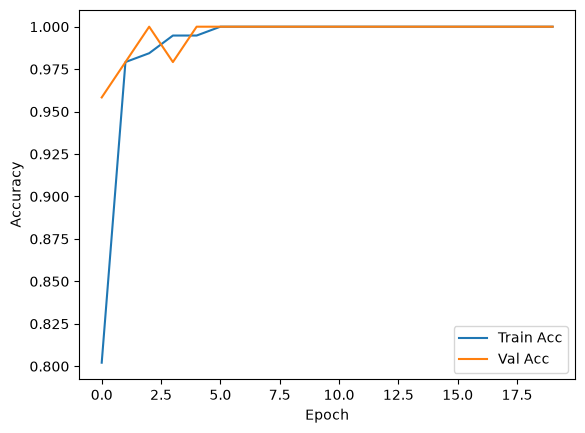

In [15]:
# Visualize training history
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

#### Langkah 12: Menyimpan Model dan Scaler

In [16]:
# Save the trained model
import pickle
Path('daynight-project').mkdir(exist_ok=True)

# 1. Simpan Model
# Menggunakan format .h5 (tanpa state optimizer Adam: tidak dibutuhkan untuk inferensi, ukuran 53 MB -> 18 MB)
model.save('daynight-project/day_night_model.h5', include_optimizer=False)
print("✅ Model berhasil disimpan sebagai: day_night_model.h5")

# 2. Simpan Scaler
with open('daynight-project/scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)
print("✅ Scaler berhasil disimpan sebagai: scaler.pkl")
for f in sorted(Path('daynight-project').glob('*')):
    print(f'{f.name:22s} {f.stat().st_size / 1e6:6.2f} MB')

✅ Model berhasil disimpan sebagai: day_night_model.h5
✅ Scaler berhasil disimpan sebagai: scaler.pkl
Dockerfile               0.00 MB
README.md                0.00 MB
app.py                   0.00 MB
day_night_model.h5      17.77 MB
requirements.txt         0.00 MB
scaler.pkl               0.83 MB


## Perbandingan dengan pendekatan fitur lain

Dataset siang/malam yang sama dipakai di JS11 dengan fitur warna. Untuk menilai pilihan fitur HOG pada modul,
tiga pendekatan dibandingkan pada split train/test yang sama:
1. **Rata-rata kecerahan (V HSV) + threshold** (baseline JS11 Praktikum 5). Threshold dipilih dari data training.
2. **Histogram HSV 3D (8×8×8) + SVM RBF.** Histogram warna mengikuti *color indexing* (Swain & Ballard, 1991), dengan SVM (Cortes & Vapnik, 1995).
3. **HOG + NN** (modul). HOG (Dalal & Triggs, 2005) menangkap distribusi arah tepi, bukan warna.

In [17]:
import pandas as pd
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score

def brightness(imgs):
    return np.array([cv2.cvtColor(im, cv2.COLOR_RGB2HSV)[..., 2].mean() for im in imgs])

def hsv_hist(imgs):
    out = []
    for im in imgs:
        h = cv2.calcHist([cv2.cvtColor(im, cv2.COLOR_RGB2HSV)], [0, 1, 2], None, [8, 8, 8], [0, 180, 0, 256, 0, 256])
        out.append(cv2.normalize(h, h).flatten())
    return np.array(out)

y_train_full = np.array([label_encoder(l) for _, l in train_img])
b_tr, b_te = brightness(X_train_img), brightness(X_test_img)
thresholds = np.arange(0, 256)
best_t = thresholds[np.argmax([((b_tr > t).astype(int) == y_train_full).mean() for t in thresholds])]
p_bright = (b_te > best_t).astype(int)

svm = SVC(kernel='rbf', C=10, gamma='scale').fit(hsv_hist(X_train_img), y_train_full)
p_svm = svm.predict(hsv_hist(X_test_img))
p_nn = y_pred.ravel()

pd.DataFrame([
    {'pendekatan': f'Kecerahan rata-rata + threshold ({best_t})', 'dimensi_fitur': 1, 'test_acc': accuracy_score(y_test, p_bright), 'F1_day': f1_score(y_test, p_bright)},
    {'pendekatan': 'Histogram HSV 8x8x8 + SVM RBF', 'dimensi_fitur': 512, 'test_acc': accuracy_score(y_test, p_svm), 'F1_day': f1_score(y_test, p_svm)},
    {'pendekatan': 'HOG + NN 128-64-1 (modul)', 'dimensi_fitur': X_train_feat.shape[1], 'test_acc': accuracy_score(y_test, p_nn), 'F1_day': f1_score(y_test, p_nn)},
]).set_index('pendekatan').round(4)

,dimensi_fitur,test_acc,F1_day
pendekatan,,,
Kecerahan rata-rata + threshold (103),1,0.9250,0.9268
Histogram HSV 8x8x8 + SVM RBF,512,0.9875,0.9875
HOG + NN 128-64-1 (modul),34596,0.9062,0.9091


Jumlah salah HOG+NN: 15


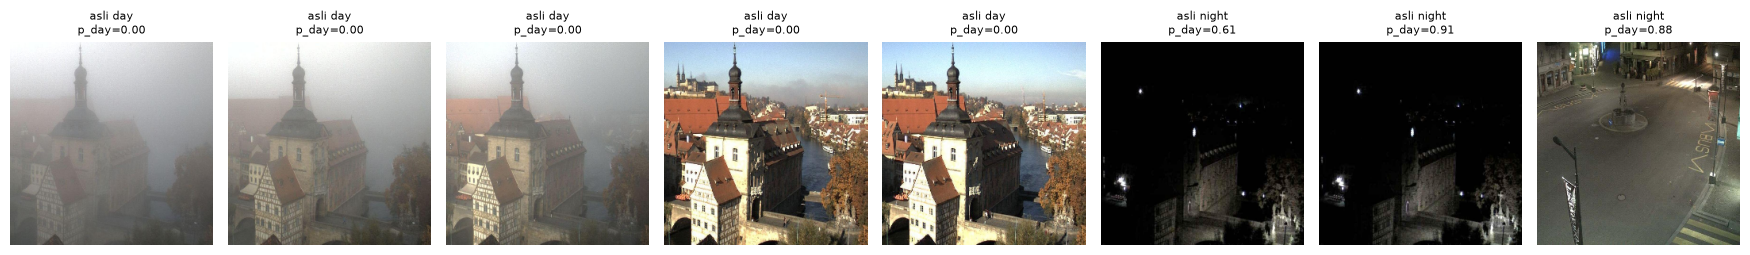

In [18]:
wrong = np.where(p_nn != y_test)[0]
print('Jumlah salah HOG+NN:', len(wrong))
if len(wrong):
    fig, ax = plt.subplots(1, min(8, len(wrong)), figsize=(2.2 * min(8, len(wrong)), 2.6), squeeze=False)
    for a, i in zip(ax[0], wrong[:8]):
        a.imshow(X_test_img[i]); a.axis('off')
        a.set_title(f"asli {'day' if y_test[i] else 'night'}\np_day={y_pred_prob[i][0]:.2f}", fontsize=8)
    plt.tight_layout(); plt.show()

## Analisis

**Hasil kode modul:** akurasi test **90,63%** (145/160). Dari confusion matrix, 10 citra malam diprediksi siang dan 5 citra siang diprediksi malam, dengan recall *day* 0,94 dan recall *night* 0,88. Akurasi train dan validasi sudah mencapai 100% sejak epoch 6, tetapi akurasi test hanya 90,63%. Validasi 48 citra diambil dari folder *training* yang sama, sehingga tidak mewakili variasi citra di folder *test*. Model memiliki **4,44 juta parameter** untuk hanya 192 citra latih, karena input HOG berdimensi 34.596 (31 × 31 blok × 2 × 2 sel × 9 orientasi). Rasio parameter terhadap data seperti ini sangat rentan overfitting.

| Pendekatan | Dimensi fitur | Akurasi test | F1 (day) |
| --- | --- | --- | --- |
| Kecerahan rata-rata + threshold 103 | 1 | 92,50% | 0,927 |
| **Histogram HSV 8×8×8 + SVM RBF** | 512 | **98,75%** | **0,988** |
| HOG + NN 128-64-1 (modul) | 34.596 | 90,63% | 0,909 |

* **HOG kalah dari fitur warna sederhana.** HOG dirancang Dalal & Triggs (2005) untuk mendeteksi **bentuk** (siluet manusia) melalui histogram arah gradien yang dinormalisasi per blok. Normalisasi kontras L2-Hys justru menghilangkan informasi utama pembeda siang dan malam, yaitu tingkat kecerahan dan warna langit. HOG baru mengenali kelas secara tidak langsung, misalnya dari tepi lampu atau langit yang gelap dan datar.
* **Histogram warna** (Swain & Ballard, 1991) langsung mengukur distribusi hue, saturation, dan value. Hasilnya dengan SVM RBF (Cortes & Vapnik, 1995) mencapai 98,75%. Temuan ini sejalan dengan Tugas JS11, yang memperoleh 97,5% dengan histogram HSV pada split 80:20 dari data yang sama. Bahkan satu angka kecerahan rata-rata sudah lebih akurat daripada pipeline HOG + NN.
* Pelajaran pipeline: pemilihan fitur harus sesuai sifat masalah, dan model yang lebih besar tidak menutupi fitur yang kurang relevan. Untuk deployment, ukuran artefak juga penting. Model HOG + NN berukuran 18 MB (sudah tanpa state optimizer; dengan optimizer 53 MB), sedangkan histogram HSV + SVM hanya beberapa ratus KB. Model yang lebih kecil mempercepat *cold start* container. Sculley dkk. (2015) menekankan bahwa kompleksitas pipeline yang tidak perlu menambah *technical debt*.
* Pada Praktikum 2, model modul tetap dideploy karena mengikuti jobsheet. Pendekatan HSV + SVM menjadi kandidat perbaikan berikutnya.

## Rujukan

1. Dalal, N., & Triggs, B. (2005). Histograms of oriented gradients for human detection. *IEEE Computer Society Conference on Computer Vision and Pattern Recognition (CVPR)*, 1, 886-893. https://doi.org/10.1109/CVPR.2005.177
2. Swain, M. J., & Ballard, D. H. (1991). Color indexing. *International Journal of Computer Vision*, 7(1), 11-32. https://doi.org/10.1007/BF00130487
3. Cortes, C., & Vapnik, V. (1995). Support-vector networks. *Machine Learning*, 20(3), 273-297. https://doi.org/10.1007/BF00994018
4. Sculley, D., Holt, G., Golovin, D., Davydov, E., Phillips, T., Ebner, D., Chaudhary, V., Young, M., Crespo, J.-F., & Dennison, D. (2015). Hidden technical debt in machine learning systems. *Advances in Neural Information Processing Systems 28 (NeurIPS)*, 2503-2511.